In [1]:
from pathlib import Path
from urllib.request import urlopen
import json

import pandas as pd
import plotly.graph_objects as go

# Local street-network input
CSV_PATH = Path.home() / "Downloads" / "manhattan_street_capacities (1).csv"

# NYC Open Data: Community Districts (Department of City Planning)
DISTRICTS_URL = (
    "https://data.cityofnewyork.us/api/v3/views/5crt-au7u/"
    "query.geojson?accessType=DOWNLOAD"
)

if not CSV_PATH.exists():
    raise FileNotFoundError(f"Street CSV not found: {CSV_PATH}")

In [2]:
# Keep only the endpoint coordinates needed to draw street segments.
streets = pd.read_csv(CSV_PATH)
coordinate_columns = ["u_lat", "u_lon", "v_lat", "v_lon"]
missing_columns = set(coordinate_columns) - set(streets.columns)
if missing_columns:
    raise ValueError(f"Street CSV is missing columns: {sorted(missing_columns)}")

for column in coordinate_columns:
    streets[column] = pd.to_numeric(streets[column], errors="coerce")
streets = streets.dropna(subset=coordinate_columns)

# Fetch the official district boundaries and retain Manhattan CDs 01–12.
with urlopen(DISTRICTS_URL, timeout=60) as response:
    district_data = json.load(response)

district_codes = [f"1{number:02d}" for number in range(1, 13)]

def normalize_borocd(value):
    """Normalize a BoroCD value (for example, 101) to a 3-digit string."""
    try:
        return f"{int(float(value)):03d}"
    except (TypeError, ValueError):
        return ""

manhattan_features = [
    feature
    for feature in district_data["features"]
    if normalize_borocd(feature.get("properties", {}).get("boro_cd")) in district_codes
]
found_codes = {
    normalize_borocd(feature["properties"]["boro_cd"])
    for feature in manhattan_features
}
missing_districts = sorted(set(district_codes) - found_codes)
if missing_districts:
    raise ValueError(f"Expected Manhattan BoroCDs 101–112; missing: {missing_districts}")

manhattan_features.sort(
    key=lambda feature: normalize_borocd(feature["properties"]["boro_cd"])
)
manhattan_geojson = {"type": "FeatureCollection", "features": manhattan_features}
print(f"Street segments: {len(streets):,} | Manhattan Community Districts: {len(manhattan_features)}")

Street segments: 9,916 | Manhattan Community Districts: 12


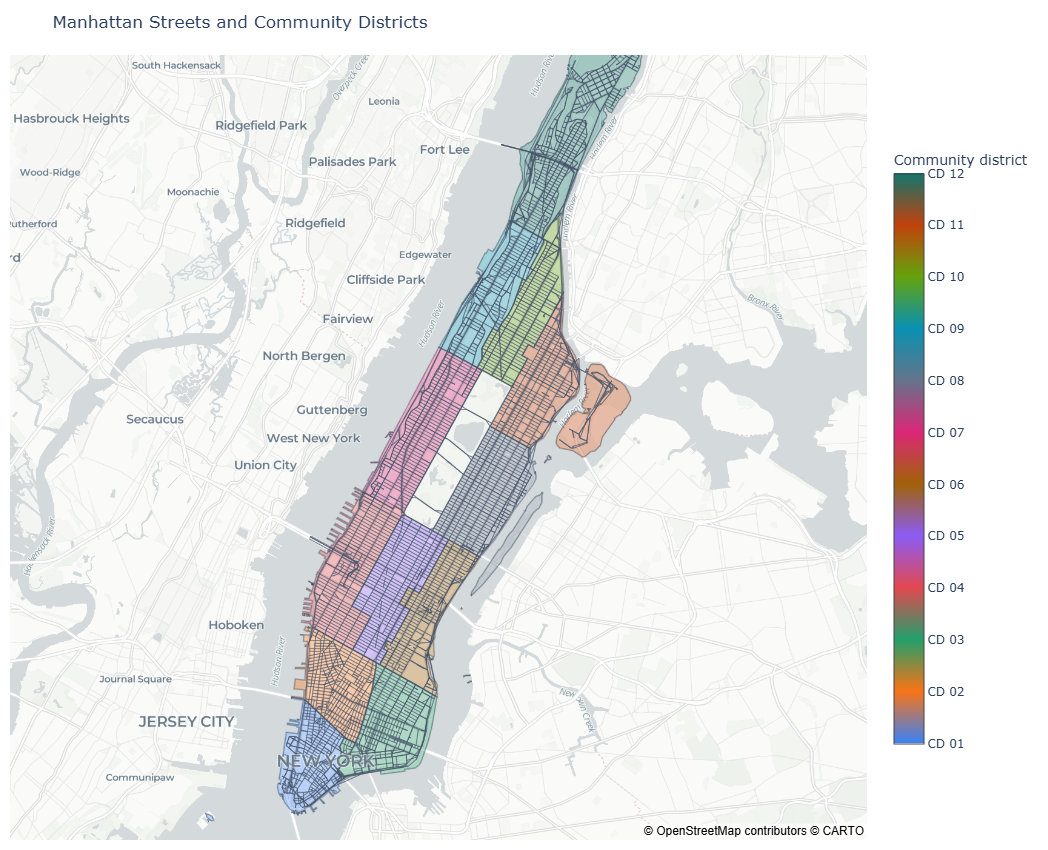

In [4]:
# Build one connected line trace from the CSV endpoint pairs.
street_lats, street_lons = [], []
for row in streets.itertuples(index=False):
    street_lats.extend([row.u_lat, row.v_lat, None])
    street_lons.extend([row.u_lon, row.v_lon, None])

district_numbers = list(range(1, 13))
district_labels = [f"Manhattan CD {number:02d}" for number in district_numbers]
district_colors = [
    "#3B82F6", "#F97316", "#22A06B", "#E34850",
    "#8B5CF6", "#A16207", "#DB2777", "#64748B",
    "#0891B2", "#65A30D", "#C2410C", "#0F766E",
]
district_colorscale = [
    [(number - 1) / 11, color]
    for number, color in zip(district_numbers, district_colors)
]
district_values = [
    int(normalize_borocd(feature["properties"]["boro_cd"])[-2:])
    for feature in manhattan_features
]

fig = go.Figure()
fig.add_trace(go.Choroplethmap(
    geojson=manhattan_geojson,
    locations=[feature["properties"]["boro_cd"] for feature in manhattan_features],
    z=district_values,
    featureidkey="properties.boro_cd",
    zmin=1,
    zmax=12,
    colorscale=district_colorscale,
    marker=dict(opacity=0.34, line=dict(color="#334155", width=1.5)),
    colorbar=dict(
        title="Community district",
        tickmode="array",
        tickvals=district_numbers,
        ticktext=[f"CD {number:02d}" for number in district_numbers],
        len=0.78,
    ),
    customdata=district_labels,
    hovertemplate="<b>%{customdata}</b><extra></extra>",
    name="Community districts",
))

fig.add_trace(go.Scattermap(
    lat=street_lats,
    lon=street_lons,
    mode="lines",
    line=dict(width=1, color="rgba(71, 85, 105, 0.72)"),
    name="Street network",
    hoverinfo="skip",
))

fig.update_layout(
    title="Manhattan Streets and Community Districts",
    map=dict(style="carto-positron", center=dict(lat=40.7831, lon=-73.9712), zoom=11.2),
    height=850,
    margin=dict(l=10, r=10, t=55, b=10),
    legend=dict(orientation="h", yanchor="bottom", y=0.01, xanchor="left", x=0.01),
)
fig.show()